## Stage 0 : Install dependencies, and Load dataset

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
# 1. Install the Hugging Face datasets library, transformers
!pip install -q datasets
!pip install -U transformers accelerate -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 90.6 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 22.8 MB/s eta 0:00:0000:01


In [3]:
# 2. Load the dataset directly into memory
from datasets import load_dataset
import pandas as pd

In [4]:
# 1. Load the dataset
dataset = load_dataset("b-mc2/sql-create-context", split="train")

# 2. Split into 80% Train and 20% Temporary (Validation + Test)
train_temp_split = dataset.train_test_split(test_size=0.2, seed=42)

# 3. Split the 20% temporary set exactly in half (0.5) to get 10% Val and 10% Test
val_test_split = train_temp_split['test'].train_test_split(test_size=0.5, seed=42)

# Extract the individual splits into their own variables
train_dataset = train_temp_split['train']       # The 80% chunk
val_dataset   = val_test_split['train']         # The first 10% chunk
test_dataset  = val_test_split['test']          # The second 10% chunk

# Verify the splits look correct
print(f"Train rows: {len(train_dataset)}")
print(f"Validation rows: {len(val_dataset)}")
print(f"Test rows: {len(test_dataset)}")


README.md:   0%|          | 0.00/4.43k [00:00<?, ?B/s]

sql_create_context_v4.json: reconstructing file:   0%|          |  0.00B / 21.8MB            

sql_create_context_v4.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/78577 [00:00<?, ? examples/s]

Train rows: 62861
Validation rows: 7858
Test rows: 7858


## Stage 1 : Know the data

In [5]:
# Print sample data
print(train_dataset[0])

{'answer': 'SELECT perth FROM table_name_56 WHERE gold_coast = "yes" AND sydney = "yes" AND melbourne = "yes" AND adelaide = "yes"', 'question': 'Which Perth has Gold Coast yes, Sydney yes, Melbourne yes, and Adelaide yes?', 'context': 'CREATE TABLE table_name_56 (perth VARCHAR, adelaide VARCHAR, melbourne VARCHAR, gold_coast VARCHAR, sydney VARCHAR)'}


### Data cleanup

In [6]:
import re
import string

def normalize_text(text):
    if not isinstance(text, str):
        return ""
    
    # 1. Convert to lowercase
    text = text.lower()
    
    # 2. Clean up whitespaces (strips edges and collapses multiple spaces into one)
    text = re.sub(r'\s+', ' ', text).strip()

    # 3. Strip trailing punctuation (?, ., !, ;) and any spaces around it
    text = re.sub(r'[\s?.!;]+$', '', text)
    
    return text

In [7]:
seen = set()
duplicates = []

for row in dataset:
        # Convert the row to a tuple of its values
    row_tuple = (normalize_text(row["question"]), 
                 normalize_text(row["context"]), 
                 normalize_text(row["answer"]))

    if row_tuple in seen:
        duplicates.append(row_tuple)
    else:
        seen.add(row_tuple)


print(f"Total rows: {len(dataset)}")
print(f"Duplicate records: {len(duplicates)}")

Total rows: 78577
Duplicate records: 3


In [8]:
search_term = "how many products are there"
matching_rows = []

for row in test_dataset:
    if search_term.lower() in row['question'].lower():
        matching_rows.append(row)

matching_rows

[{'answer': 'SELECT COUNT(*) FROM products WHERE product_category_code = "Seeds"',
  'question': 'How many products are there under the category "Seeds"?',
  'context': 'CREATE TABLE products (product_category_code VARCHAR)'}]

In [9]:
def make_key(row):
    row_tuple = (normalize_text(row["question"]), 
             normalize_text(row["context"]), 
             normalize_text(row["answer"]))
    return row_tuple

In [10]:
train_keys = {make_key(row) for row in train_dataset}

In [11]:
print('Test dataset Before Removing duplicates', len(test_dataset))
# Filter test dataset to not include duplicates
test_dataset = test_dataset.filter(lambda row: make_key(row) not in train_keys)

print('Test dataset After Removing duplicates', len(test_dataset))

Test dataset Before Removing duplicates 7858


Filter:   0%|          | 0/7858 [00:00<?, ? examples/s]

Test dataset After Removing duplicates 7857


In [12]:
print('Validation set Before Removing duplicates', len(val_dataset))
# Filter test dataset to not include duplicates
val_dataset = val_dataset.filter(lambda row: make_key(row) not in train_keys)

print('Validation After Removing duplicates', len(val_dataset))

Validation set Before Removing duplicates 7858


Filter:   0%|          | 0/7858 [00:00<?, ? examples/s]

Validation After Removing duplicates 7858


In [13]:
schema_set = set()
# Check Schema duplication
schema_set = {normalize_text(row["context"]) for row in train_dataset}

print(len(schema_set))
print(list(schema_set)[:5])

58996
['create table table_25129482_1 (stadium varchar, location varchar)', 'create table table_name_52 (cuts_made integer, events varchar, top_5 varchar, top_10 varchar)', 'create table table_name_46 (seats_2010 integer, in_de_creased_by varchar, seats_2005 varchar, governorate varchar)', 'create table table_11677691_4 (school varchar, hometown varchar)', 'create table table_name_4 (name varchar, order varchar)']


In [14]:
def add_seen_schema(row):
    return {"seen_schema": normalize_text(row["context"]) in schema_set}

val_dataset = val_dataset.map(add_seen_schema)
test_dataset = test_dataset.map(add_seen_schema)
print(sum(val_dataset["seen_schema"]) / len(val_dataset))
print(sum(test_dataset["seen_schema"]) / len(test_dataset))

Map:   0%|          | 0/7858 [00:00<?, ? examples/s]

Map:   0%|          | 0/7857 [00:00<?, ? examples/s]

0.10486128785950624
0.11060201094565356


In [15]:
duplicate_test_context = 0
for row in test_dataset:
    if normalize_text(row["context"]) in schema_set:
        duplicate_test_context += 1

print('Total test rows', len(test_dataset))
print('Rows with duplicate context',duplicate_test_context)

Total test rows 7857
Rows with duplicate context 869


In [16]:
sample = train_dataset.shuffle(seed=42).select(range(15))

for i, row in enumerate(sample):
    print(f"--- {i} ---")
    print("Q:      ", row["question"])
    print("CONTEXT:", row["context"])
    print("ANSWER: ", row["answer"])
    print()

--- 0 ---
Q:       Show institution types, along with the number of institutions and total enrollment for each type.
CONTEXT: CREATE TABLE institution (TYPE VARCHAR, enrollment INTEGER)
ANSWER:  SELECT TYPE, COUNT(*), SUM(enrollment) FROM institution GROUP BY TYPE

--- 1 ---
Q:       What is the listed in games played when the player is jimmy alapag?
CONTEXT: CREATE TABLE table_28628309_8 (games_played VARCHAR, player VARCHAR)
ANSWER:  SELECT games_played FROM table_28628309_8 WHERE player = "Jimmy Alapag"

--- 2 ---
Q:       What is the record for the loss in UFC 62?
CONTEXT: CREATE TABLE table_name_26 (record VARCHAR, res VARCHAR, event VARCHAR)
ANSWER:  SELECT record FROM table_name_26 WHERE res = "loss" AND event = "ufc 62"

--- 3 ---
Q:       how many 5wi with an average of 33.13?
CONTEXT: CREATE TABLE table_28846752_5 (average VARCHAR)
ANSWER:  SELECT COUNT(5 AS wi) FROM table_28846752_5 WHERE average = "33.13"

--- 4 ---
Q:       What Field was played at in an away game against 

In [17]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

In [18]:
prompt_length = []
answer_length = []

for row in train_dataset:
    prompt = f"Given this schema {row['context']}, write a SQL query for {row['question']}"
    p_length = len(tokenizer.tokenize(prompt))
    prompt_length.append(p_length)

    a_length = len(tokenizer.tokenize(row['answer']))
    answer_length.append(a_length)
    



In [19]:
import numpy as np

prompt_len = np.array(prompt_length)
answer_len = np.array(answer_length)
total_len = prompt_len + answer_len      # per example, so this is valid

for name, arr in [("prompt", prompt_len), ("answer", answer_len), ("total", total_len)]:
    p50, p95, p99 = np.percentile(arr, [50,95,99])
    print(f"{name:7s} median={p50:.0f}  p95={p95:.0f}  p99={p99:.0f}  max={arr.max()}")

prompt  median=42  p95=62  p99=76  max=231
answer  median=24  p95=39  p99=52  max=214
total   median=66  p95=100  p99=125  max=444


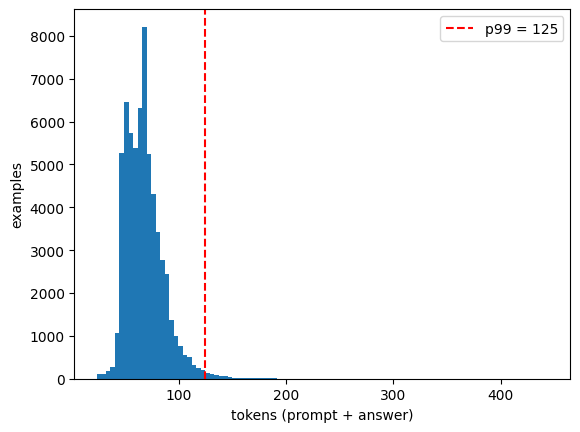

In [20]:
import matplotlib.pyplot as plt

p99 = np.percentile(total_len, 99)
plt.hist(total_len, bins=100)
plt.axvline(p99, color="red", linestyle="--", label=f"p99 = {p99:.0f}")
plt.xlabel("tokens (prompt + answer)")
plt.ylabel("examples")
plt.legend()
plt.show()

## Stage 2 : Evaluation

In [22]:
import sqlite3
schema_errors = 0
query_errors = 0

def check_sql(context, answer):
    conn = sqlite3.connect(':memory:')
    cursor = conn.cursor()

    try:
        cursor.executescript(context)
    except Exception as e:
        return "schema_error", e

    
    try:
        cursor.executescript(answer)
    except Exception as e:
        return "query_error", e


    return "ok", None


def add_gold_status(row):
    status, message = check_sql(row['context'], row['answer'])
    return {"gold_status": status, "gold_error": message or ""}

val_dataset= val_dataset.map(add_gold_status)
test_dataset= test_dataset.map(add_gold_status)

Map:   0%|          | 0/7858 [00:00<?, ? examples/s]

Map:   0%|          | 0/7857 [00:00<?, ? examples/s]

In [23]:
from collections import Counter
print(Counter(val_dataset["gold_status"]))

errors = val_dataset.filter(lambda r: r["gold_status"] != "ok")
# for r in errors:
#     print(r["gold_status"], "|", r["gold_error"], "|", r["answer"])

Counter({'ok': 7703, 'query_error': 126, 'schema_error': 29})


Filter:   0%|          | 0/7858 [00:00<?, ? examples/s]

In [24]:
eval_set = val_dataset.shuffle(seed=42).select(range(200))
eval_set.filter(lambda x:x['gold_status'] == 'ok')

Filter:   0%|          | 0/200 [00:00<?, ? examples/s]

Dataset({
    features: ['answer', 'question', 'context', 'seen_schema', 'gold_status', 'gold_error'],
    num_rows: 197
})

In [25]:
def normalize_sql(query):
    if not isinstance(query, str):
        return ""
    
    # 1. Convert to lowercase
    query = query.lower()
    
    # 2. Clean up whitespaces (strips edges and collapses multiple spaces into one)
    query = re.sub(r'\s+', ' ', query).strip()

    # 3. Strip trailing punctuation (?, ., !, ;) and any spaces around it
    query = re.sub(r'[\s?.!;]+$', '', query)

    # 4. Convert double quotes to single quotes
    query = query.replace('"', "'")
    
    return query

In [26]:
def summarize(records):
    if not records:
        return {"n": 0, "exact_match": None, "runs_in_sqlite": None, "skipped": 0}
    em = sum(r["match"] for r in records) / len(records) * 100
    scored = [r for r in records if r["sqlite"] != "skipped"]
    sqlite_pct = (sum(r["sqlite"] == "ok" for r in scored) / len(scored) * 100) if scored else None
    return {
        "n": len(records),
        "exact_match": em,
        "runs_in_sqlite": sqlite_pct,
        "skipped": len(records) - len(scored),
    }


def evaluate(preds, dev_rows):
    records = []
    for pred, row in zip(preds, dev_rows):
        cleaned_pred = normalize_sql(pred)
        match =  cleaned_pred == normalize_sql(row["answer"])
        
        if row["gold_status"] != "ok":
            status, message = "skipped", ""
        elif cleaned_pred == '':
            status, message = "query_error", "empty prediction"
        else:
            status, message = check_sql(row["context"], pred)

        records.append({
            "pred": pred,
            "gold": row["answer"],
            "match": match,
            "sqlite": status,
            "error": message or "",
            "seen_schema": row["seen_schema"],
        })

    report = {
        "all": summarize(records),
        "seen_schema": summarize([r for r in records if r["seen_schema"]]),
        "new_schema": summarize([r for r in records if not r["seen_schema"]]),
        # "records": records,
    }

    for group in ["all", "seen_schema", "new_schema"]:
        s = report[group]
        print(f"{group:12s} n={s['n']:4d}  exact_match={s['exact_match']}  "
              f"runs_in_sqlite={s['runs_in_sqlite']}  skipped={s['skipped']}")
    return report

In [27]:
print(evaluate(eval_set['answer'], eval_set))

all          n= 200  exact_match=100.0  runs_in_sqlite=100.0  skipped=3
seen_schema  n=  19  exact_match=100.0  runs_in_sqlite=100.0  skipped=0
new_schema   n= 181  exact_match=100.0  runs_in_sqlite=100.0  skipped=3
{'all': {'n': 200, 'exact_match': 100.0, 'runs_in_sqlite': 100.0, 'skipped': 3}, 'seen_schema': {'n': 19, 'exact_match': 100.0, 'runs_in_sqlite': 100.0, 'skipped': 0}, 'new_schema': {'n': 181, 'exact_match': 100.0, 'runs_in_sqlite': 100.0, 'skipped': 3}}


In [28]:
# Noisy preds, meaning unchanged
def add_noise(sql, i):
    variants = [
        lambda s: s.upper(),
        lambda s: s.lower(),
        lambda s: "  " + s.replace(" ", "   ") + "  ",
        lambda s: s.replace(" WHERE ", "\nWHERE "),
        lambda s: s + ";",
        lambda s: s.replace('"', "'"),
    ]
    return variants[i % len(variants)](sql)   # cycle through, a different change per row

noisy_preds = [add_noise(r["answer"], i) for i, r in enumerate(eval_set)]

print(evaluate(noisy_preds, eval_set))


all          n= 200  exact_match=100.0  runs_in_sqlite=99.49238578680203  skipped=3
seen_schema  n=  19  exact_match=100.0  runs_in_sqlite=94.73684210526315  skipped=0
new_schema   n= 181  exact_match=100.0  runs_in_sqlite=100.0  skipped=3
{'all': {'n': 200, 'exact_match': 100.0, 'runs_in_sqlite': 99.49238578680203, 'skipped': 3}, 'seen_schema': {'n': 19, 'exact_match': 100.0, 'runs_in_sqlite': 94.73684210526315, 'skipped': 0}, 'new_schema': {'n': 181, 'exact_match': 100.0, 'runs_in_sqlite': 100.0, 'skipped': 3}}


In [29]:
# Broken preds : Meaning changed
import re

def break_operator(sql):
    broken = re.sub(r"\s=\s", " != ", sql, count=1)
    return broken if broken != sql else sql + " AND 1 = 0"   # fallback if there's no "="

def break_column(sql):
    return re.sub(r"^\s*SELECT\s+", "SELECT nonexistent_col, ", sql, count=1, flags=re.I)

broken_preds = []
for i, r in enumerate(eval_set):
    gold = r["answer"]
    if i < 25:
        broken_preds.append(break_operator(gold))
    elif i < 50:
        broken_preds.append(break_column(gold))
    else:
        broken_preds.append(gold)

# Make sure every break really changed the query
for i in range(50):
    assert normalize_sql(broken_preds[i]) != normalize_sql(eval_set[i]["answer"]), i


print(evaluate(broken_preds, eval_set))

all          n= 200  exact_match=75.0  runs_in_sqlite=86.80203045685279  skipped=3
seen_schema  n=  19  exact_match=78.94736842105263  runs_in_sqlite=89.47368421052632  skipped=0
new_schema   n= 181  exact_match=74.58563535911603  runs_in_sqlite=86.51685393258427  skipped=3
{'all': {'n': 200, 'exact_match': 75.0, 'runs_in_sqlite': 86.80203045685279, 'skipped': 3}, 'seen_schema': {'n': 19, 'exact_match': 78.94736842105263, 'runs_in_sqlite': 89.47368421052632, 'skipped': 0}, 'new_schema': {'n': 181, 'exact_match': 74.58563535911603, 'runs_in_sqlite': 86.51685393258427, 'skipped': 3}}


In [30]:
empty_preds = [""] * len(eval_set)
print(evaluate(empty_preds, eval_set))
prose_preds = ["Here is the query: I don't know"] * len(eval_set)
print(evaluate(prose_preds, eval_set))

all          n= 200  exact_match=0.0  runs_in_sqlite=0.0  skipped=3
seen_schema  n=  19  exact_match=0.0  runs_in_sqlite=0.0  skipped=0
new_schema   n= 181  exact_match=0.0  runs_in_sqlite=0.0  skipped=3
{'all': {'n': 200, 'exact_match': 0.0, 'runs_in_sqlite': 0.0, 'skipped': 3}, 'seen_schema': {'n': 19, 'exact_match': 0.0, 'runs_in_sqlite': 0.0, 'skipped': 0}, 'new_schema': {'n': 181, 'exact_match': 0.0, 'runs_in_sqlite': 0.0, 'skipped': 3}}
all          n= 200  exact_match=0.0  runs_in_sqlite=0.0  skipped=3
seen_schema  n=  19  exact_match=0.0  runs_in_sqlite=0.0  skipped=0
new_schema   n= 181  exact_match=0.0  runs_in_sqlite=0.0  skipped=3
{'all': {'n': 200, 'exact_match': 0.0, 'runs_in_sqlite': 0.0, 'skipped': 3}, 'seen_schema': {'n': 19, 'exact_match': 0.0, 'runs_in_sqlite': 0.0, 'skipped': 0}, 'new_schema': {'n': 181, 'exact_match': 0.0, 'runs_in_sqlite': 0.0, 'skipped': 3}}


## Stage 3 : Baseline

Prompt a small base model (Qwen 0.5B to 1.5B Instruct, ungated) zero-shot on 200 held-out examples


In [31]:
from transformers import AutoTokenizer, AutoModelForCausalLM

model_id = "Qwen/Qwen2.5-0.5B-Instruct"
# Load the model onto the available GPU
# Note: On T4 GPUs, use float16/bfloat16 to optimize memory allocation
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype="auto", 
    device_map="auto"
)


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [32]:

def chat_completion(messages, model = model, tokenizer = tokenizer, **kwargs):
    
    # Apply the prompt template
    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    
    # Tokenize and push to GPU
    model_inputs = tokenizer([text], return_tensors="pt").to(model.device)
    
    # Generate response
    generated_ids = model.generate(
        **model_inputs,
        max_new_tokens=256,
        temperature=0.7
    )
    
    # Extract only the newly generated tokens
    generated_ids = [
        output_ids[len(input_ids):] for input_ids, output_ids in zip(model_inputs.input_ids, generated_ids)
    ]
    
    # Decode and print
    response = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)[0]
    return response



In [33]:
# Format your chat structure
messages = [
    {"role": "system", "content": "You are a helpful and concise assistant."},
    {"role": "user", "content": "Explain what a Kaggle Notebook is in one sentence."}
]

print(chat_completion(messages=messages))

A Kaggle Notebook is a code-based document that outlines the problem to be solved, data preparation steps, algorithm selection, model training, evaluation, and results interpretation for a machine learning competition on Kaggle.


In [34]:
system_prompt = """ You are a SQLite expert. Given a database schema and a question, write one SQLite query that answers the question.

Rules:
- Use only the tables and columns in the schema.
- Return only the SQL query: no explanation, no markdown, no code fences.
- Write a single SELECT statement. 

""" 

user_message_template = """
Schema:
{context}

Question: {question}
"""

In [36]:
preds = []
random_dev_data = eval_set.shuffle(seed=42).select(range(20))


for row in random_dev_data:
    
    user_message = user_message_template.format(context=row['context'], 
                                                question=row['question'])
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_message}
    ]
    # print(row['answer'][0])
    preds.append(chat_completion(messages=messages))

In [37]:
random_dev_data['answer'], preds

(Column(['SELECT year FROM table_name_90 WHERE manufacturer = "letecke zavody n.p., jinonice"', 'SELECT score FROM table_name_29 WHERE date > 7 AND game = 82', 'SELECT SUM(overall) FROM table_name_23 WHERE pick < 8 AND college = "western michigan"', 'SELECT MIN(place) FROM table_26375386_28 WHERE couple = "Keiron & Brianne"', 'SELECT game FROM table_27755603_11 WHERE team = "Chicago"', ...]),
 ["SELECT year FROM table_name_90 WHERE manufacturer = 'Letecke Zavody N.P., Jinonice'",
  'SELECT score FROM table_name_29 WHERE date > 7 AND game = "82"',
  'SELECT SUM(overall) FROM table_name_23 WHERE pick < 8 AND college = "western michigan"',
  'SELECT MIN(place) FROM table_26375386_28 WHERE couple = "Keiron & Brianne"',
  'SELECT T1.game FROM table_27755603_11 AS T1 JOIN team AS T2 ON T1.team = T2.name WHERE T2.name = "Chicago" ORDER BY T1.game ASC LIMIT 1',
  'SELECT date FROM table_name_22 WHERE visitor = "Chicago"',
  'SELECT title, directed_by FROM film',
  "SELECT actor FROM table_name

In [38]:
print(evaluate(preds, random_dev_data))

all          n=  20  exact_match=50.0  runs_in_sqlite=85.0  skipped=0
seen_schema  n=   1  exact_match=0.0  runs_in_sqlite=0.0  skipped=0
new_schema   n=  19  exact_match=52.63157894736842  runs_in_sqlite=89.47368421052632  skipped=0
{'all': {'n': 20, 'exact_match': 50.0, 'runs_in_sqlite': 85.0, 'skipped': 0}, 'seen_schema': {'n': 1, 'exact_match': 0.0, 'runs_in_sqlite': 0.0, 'skipped': 0}, 'new_schema': {'n': 19, 'exact_match': 52.63157894736842, 'runs_in_sqlite': 89.47368421052632, 'skipped': 0}}


In [43]:
for i, (gold_answer, pred) in enumerate(zip(random_dev_data['answer'], preds), 1):
    print(f"--- Instance {i} ---")
    print(f"Gold Answer : {gold_answer}")
    print(f"Prediction  : {pred}\n")

--- Instance 1 ---
Gold Answer : SELECT year FROM table_name_90 WHERE manufacturer = "letecke zavody n.p., jinonice"
Prediction  : SELECT year FROM table_name_90 WHERE manufacturer = 'Letecke Zavody N.P., Jinonice'

--- Instance 2 ---
Gold Answer : SELECT score FROM table_name_29 WHERE date > 7 AND game = 82
Prediction  : SELECT score FROM table_name_29 WHERE date > 7 AND game = "82"

--- Instance 3 ---
Gold Answer : SELECT SUM(overall) FROM table_name_23 WHERE pick < 8 AND college = "western michigan"
Prediction  : SELECT SUM(overall) FROM table_name_23 WHERE pick < 8 AND college = "western michigan"

--- Instance 4 ---
Gold Answer : SELECT MIN(place) FROM table_26375386_28 WHERE couple = "Keiron & Brianne"
Prediction  : SELECT MIN(place) FROM table_26375386_28 WHERE couple = "Keiron & Brianne"

--- Instance 5 ---
Gold Answer : SELECT game FROM table_27755603_11 WHERE team = "Chicago"
Prediction  : SELECT T1.game FROM table_27755603_11 AS T1 JOIN team AS T2 ON T1.team = T2.name WHERE 